# Analisis Sentimen Ulasan Gojek

**Eksperimen Submission 1 — Belajar Fundamental Deep Learning (Dicoding)**

Notebook ini berisi proses analisis sentimen ulasan Gojek dari Google Play Store menggunakan tiga skema klasifikasi: **LinearSVC**, **Logistic Regression**, dan **Bidirectional LSTM**. Label yang diprediksi meliputi **negatif, netral, dan positif**.

Implementasi yang terdokumentasi menggunakan **PyTorch** dan preprocessing offline. Eksperimen sebelumnya menggunakan TensorFlow/Keras, NLTK, dan PySastrawi; hasilnya diperlakukan sebagai eksperimen terpisah karena pendekatan preprocessing dan framework berbeda. Output numerik dan visualisasi di bawah merupakan hasil eksekusi notebook yang tersimpan.


## I. Persiapan lingkungan

Dependensi tersedia di `requirements.txt` dan dapat dipasang menggunakan `python -m pip install -r requirements.txt`. Notebook dapat dijalankan dari root repository maupun folder `notebooks/`.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import torch
from IPython.display import display, Image
# Notebook dapat dijalankan dari root repository maupun direktori notebooks/.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'requirements.txt').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'data/raw/ulasan_gojek_raw.csv').exists():
    raise FileNotFoundError('Dataset tidak ditemukan. Jalankan notebook dari folder repository/notebooks.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.pipeline_gojek import SEED
print('Python:',sys.version.split()[0],'PyTorch:',torch.__version__,'Pandas:',pd.__version__,'Seed:',SEED)
assert (PROJECT_ROOT/'data/raw/ulasan_gojek_raw.csv').exists()

Python: 3.13.5 PyTorch: 2.10.0+cpu Pandas: 2.2.3 Seed: 42


## II. Pemeriksaan dataset mentah

Snapshot ulasan `data/raw/ulasan_gojek_raw.csv` diperiksa berdasarkan jumlah baris, struktur kolom, distribusi rating, dan keunikan konten ulasan.


In [2]:
raw=pd.read_csv(PROJECT_ROOT/'data/raw/ulasan_gojek_raw.csv')
print('Jumlah awal:',len(raw),'kolom:',list(raw.columns))
print('Rating bintang:',raw['score'].value_counts().sort_index().to_dict())
print('Konten unik sebelum preprocessing:',raw['content'].nunique())
display(raw.head())
assert len(raw)==15000

Jumlah awal: 15000 kolom: ['content', 'score', 'at', 'thumbsUpCount']
Rating bintang: {1: 4670, 2: 743, 3: 657, 4: 710, 5: 8220}
Konten unik sebelum preprocessing: 11748


,content,score,at,thumbsUpCount
0,Aplikasi ga tanggung jawab malah di bend akun ...,1,2026-10-18 01:36:49,0
1,banyak diskon/promo harga dan aman.,5,2026-10-18 01:20:48,0
2,sangat membantu,5,2026-10-18 01:02:49,0
3,driver gojek selalu ramah 🤗...tidak sprti driv...,5,2026-10-18 00:54:47,0
4,josss,5,2026-10-17 22:34:22,0


## III. Preprocessing dan pelabelan sentimen

Alur preprocessing meliputi **cleaning → case folding → normalisasi slang → stopword filtering → stemming ringan offline**. Setelah preprocessing, duplikat `text_stem` dihapus sebelum pembagian data. Pseudo-label diperoleh dari leksikon positif/negatif berbobot dengan penanganan negasi sederhana, dan **belum divalidasi terhadap anotasi manusia independen**.


## IV. Rancangan eksperimen

Perbandingan dilakukan pada tiga algoritma, pendekatan representasi teks, dan rasio pembagian data.

| Skema | Algoritma | Fitur | Split |
|---|---|---|---|
| 1 | LinearSVC (L1) | TF-IDF unigram/bigram | 80/20 |
| 2 | Logistic Regression (L2) | CountVectorizer unigram/bigram | 70/30 |
| 3 | Bidirectional LSTM (PyTorch) | Word embedding | 80/20, ditambah 10% validasi dari bagian training |

Vectorizer dan vocabulary hanya di-*fit* menggunakan training set. Untuk BiLSTM, checkpoint dipilih berdasarkan validation accuracy sebelum pengujian pada test set.


In [3]:
from src.train_models import run
results=run()
print('Eksekusi training selesai:', results['execution_seconds'], 'detik')

Memuat data dan membersihkan teks...


Audit: {'raw_rows': 15000, 'after_remove_missing': 15000, 'after_dedup_raw_content': 11748, 'after_drop_empty_stems': 11677, 'after_dedup_text_stem': 10863, 'stem_duplicates_removed': 814} kelas: {'negatif': 5110, 'positif': 4074, 'netral': 1679}
Melatih skema 1 (LinearSVC + TF-IDF)...


Skema 1 akurasi: 99.252 92.4988
Melatih skema 2 (Logistic Regression + BoW)...


Skema 2 akurasi: 99.7764 90.764
Melatih skema 3 (PyTorch Bidirectional LSTM)...


  Epoch 1: train=51.52% val=65.94% (9.4s)


...

  Epoch 10: train=89.41% val=88.38% (13.7s)


  Epoch 11: train=90.37% val=88.95% (15.0s)


  Epoch 12: train=91.45% val=89.99% (26.9s)


Skema 3 akurasi: 94.2335 89.0934


Hasil berhasil disimpan. Durasi: 247.78 detik
Eksekusi training selesai: 247.78 detik


## V. Pemeriksaan dataset siap latih

Dataset akhir diperiksa berdasarkan jumlah sampel, distribusi kelas, dan keunikan `text_stem`. Deduplikasi dilakukan sebelum pembuatan subset training, validation, dan testing.


Audit preprocessing:
raw_rows : 15000
after_dedup_raw_content : 11748
after_drop_empty_stems : 11677
stem_duplicates_removed : 814
rows : 10863
class_counts : {'negatif': 5110, 'positif': 4074, 'netral': 1679}


,content,text_stem,polarity_score,polarity
0,Aplikasi ga tanggung jawab malah di bend akun ...,tidak tanggung jawab bend akun saya tidak jela...,-8,negatif
1,banyak diskon/promo harga dan aman.,banyak diskon promo harga aman,8,positif
2,sangat membantu,sangat bantu,4,positif
3,driver gojek selalu ramah 🤗...tidak sprti driv...,driver selalu ramah tidak seperti driver sebel...,1,positif
4,josss,jos,4,positif


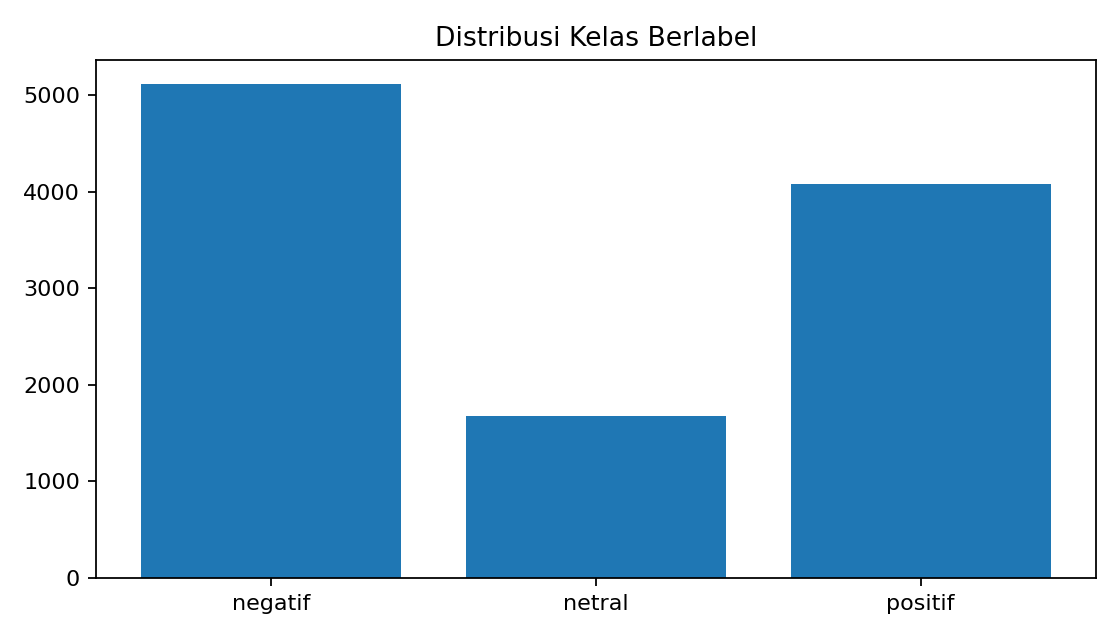

In [4]:
d=results['dataset'];print('Audit preprocessing:')
for key in ['raw_rows','after_dedup_raw_content','after_drop_empty_stems','stem_duplicates_removed','rows','class_counts']:print(key,':',d[key])
labeled=pd.read_csv(PROJECT_ROOT/'data/processed/ulasan_gojek_labeled.csv')
assert labeled['text_stem'].is_unique and len(labeled)>=10000 and labeled['polarity'].nunique()==3
display(labeled[['content','text_stem','polarity_score','polarity']].head())
display(Image(filename=str(PROJECT_ROOT/'results/figures/distribusi_kelas.png')))

## VI. Perbandingan performa model

Tabel evaluasi membandingkan akurasi training, akurasi testing, serta macro F1-score ketiga skema. Nilai terstruktur juga tersedia di `results/metrics/hasil_evaluasi_final.json`.


,scheme,algorithm,train_accuracy,test_accuracy,macro_f1
0,skema_1_linear_svc_tfidf,LinearSVC (L1),99.2520,92.4988,0.9052
1,skema_2_logreg_bow,Logistic Regression (L2),99.7764,90.7640,0.8857
2,skema_3_bilstm,PyTorch Bidirectional LSTM,94.2335,89.0934,0.8717


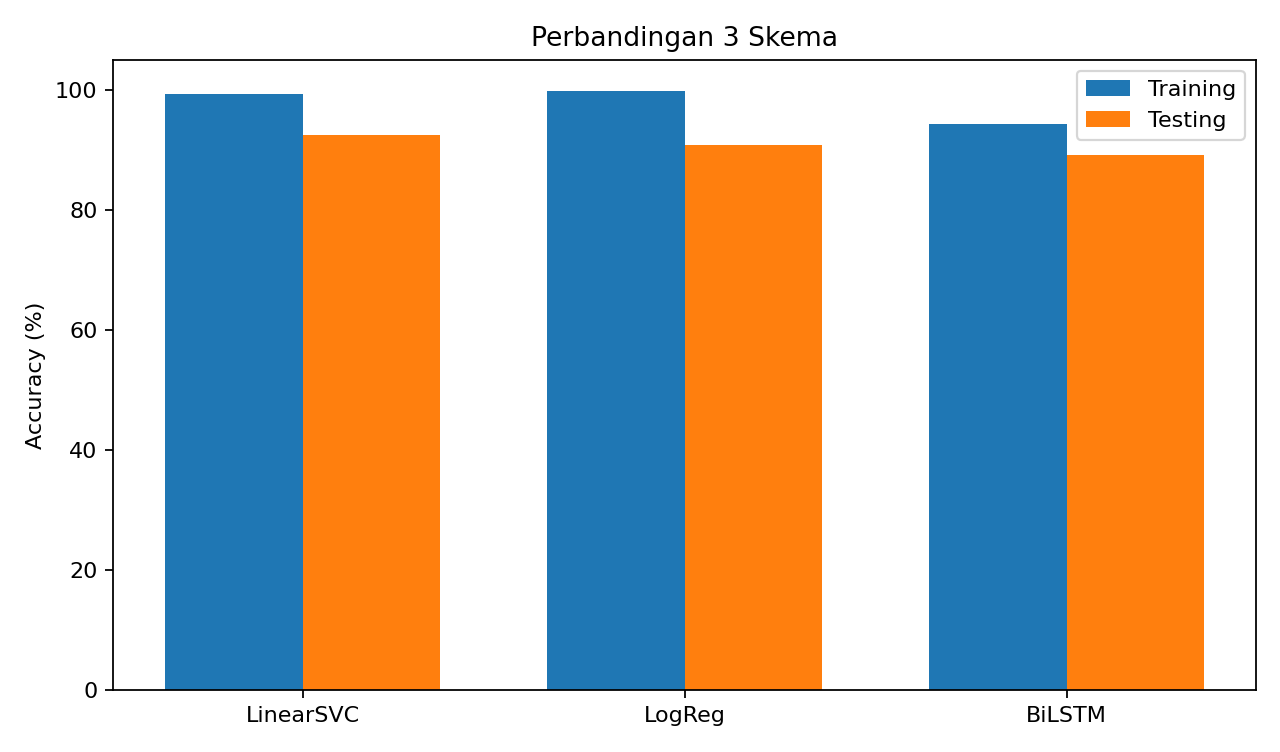

In [5]:
table=pd.read_csv(PROJECT_ROOT/'results/metrics/perbandingan_akurasi_final.csv');display(table)
display(Image(filename=str(PROJECT_ROOT/'results/figures/perbandingan_akurasi.png')))

In [6]:
for name,r in results['schemes'].items():
    print(name, 'train:',r['training_accuracy'],'test:',r['testing_accuracy'],'macro-F1:',r['testing_macro_f1'])
    print('F1 per kelas:',{label:round(r['report'][label]['f1-score'],4) for label in ['negatif','netral','positif']})

skema_1_linear_svc_tfidf train: 99.252 test: 92.4988 macro-F1: 0.9052
F1 per kelas: {'negatif': 0.9493, 'netral': 0.8369, 'positif': 0.9292}
skema_2_logreg_bow train: 99.7764 test: 90.764 macro-F1: 0.8857
F1 per kelas: {'negatif': 0.9336, 'netral': 0.8063, 'positif': 0.9172}
skema_3_bilstm train: 94.2335 test: 89.0934 macro-F1: 0.8717
F1 per kelas: {'negatif': 0.9167, 'netral': 0.8029, 'positif': 0.8956}


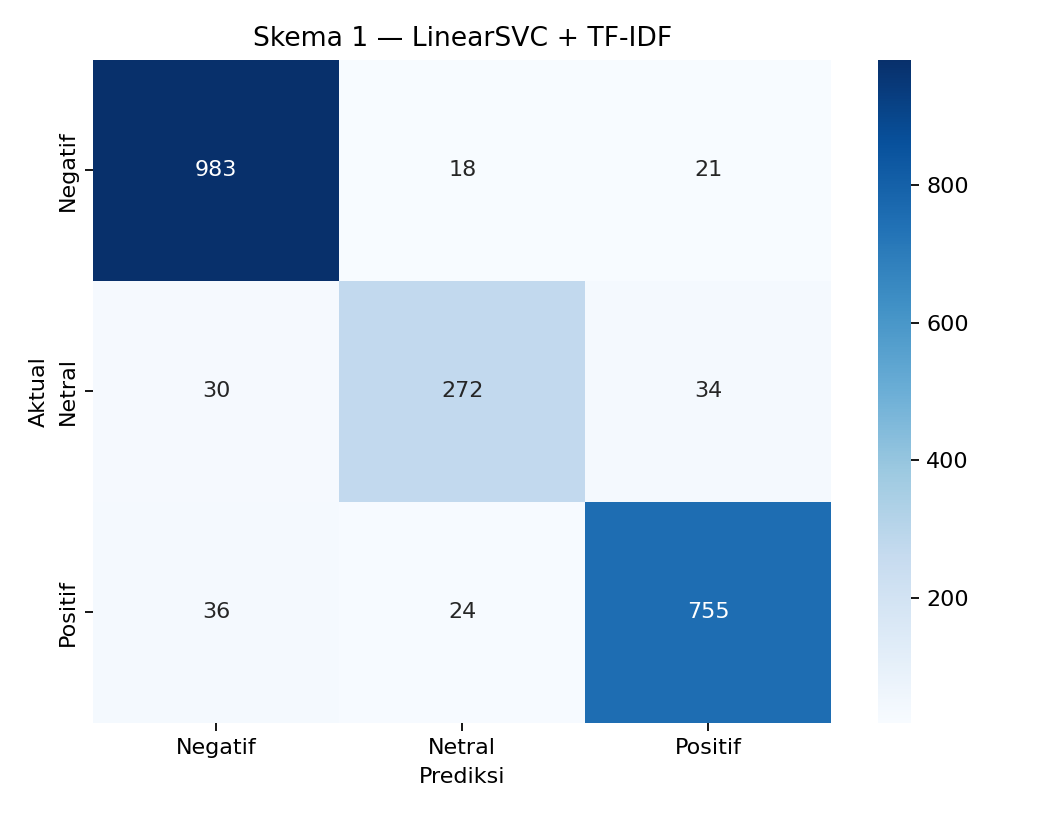

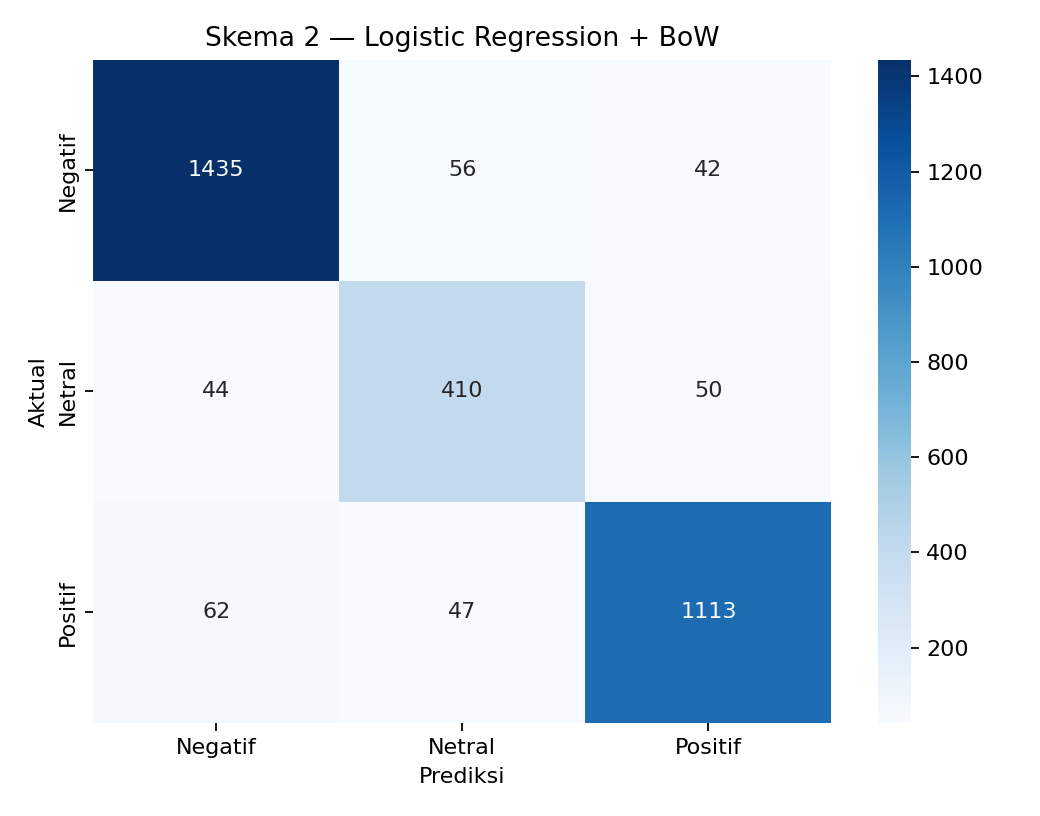

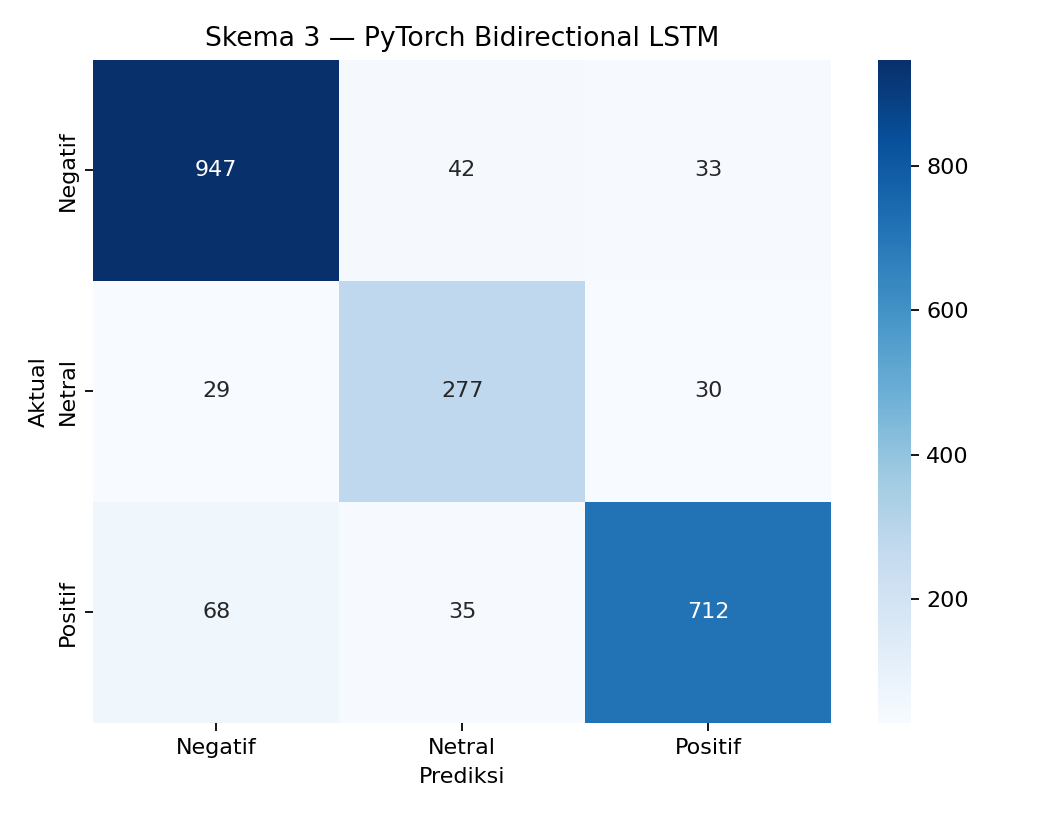

In [7]:
for i in [1,2,3]:display(Image(filename=str(PROJECT_ROOT/f'results/figures/confusion_matrix_skema_{i}.png')))

## VII. Riwayat pelatihan BiLSTM

Training dan validation set digunakan untuk memantau perkembangan pembelajaran. Bobot model dipilih berdasarkan performa validation dan dievaluasi pada testing set terpisah.


Best epoch: 12 Validation: 89.9885 Testing: 89.0934


,epoch,training_accuracy,validation_accuracy,training_loss,validation_loss
0,1,51.515,65.938,1.04555,0.97201
1,2,65.158,71.116,0.90678,0.78772
2,3,71.679,76.064,0.74450,0.65260
3,4,76.538,79.402,0.62071,0.56820
4,5,81.025,81.933,0.53256,0.50671
5,6,83.429,84.465,0.46518,0.46355
6,7,86.076,85.961,0.42309,0.42721
7,8,87.649,86.997,0.38164,0.39945
8,9,88.940,87.687,0.34659,0.37448
9,10,89.413,88.377,0.32155,0.36100


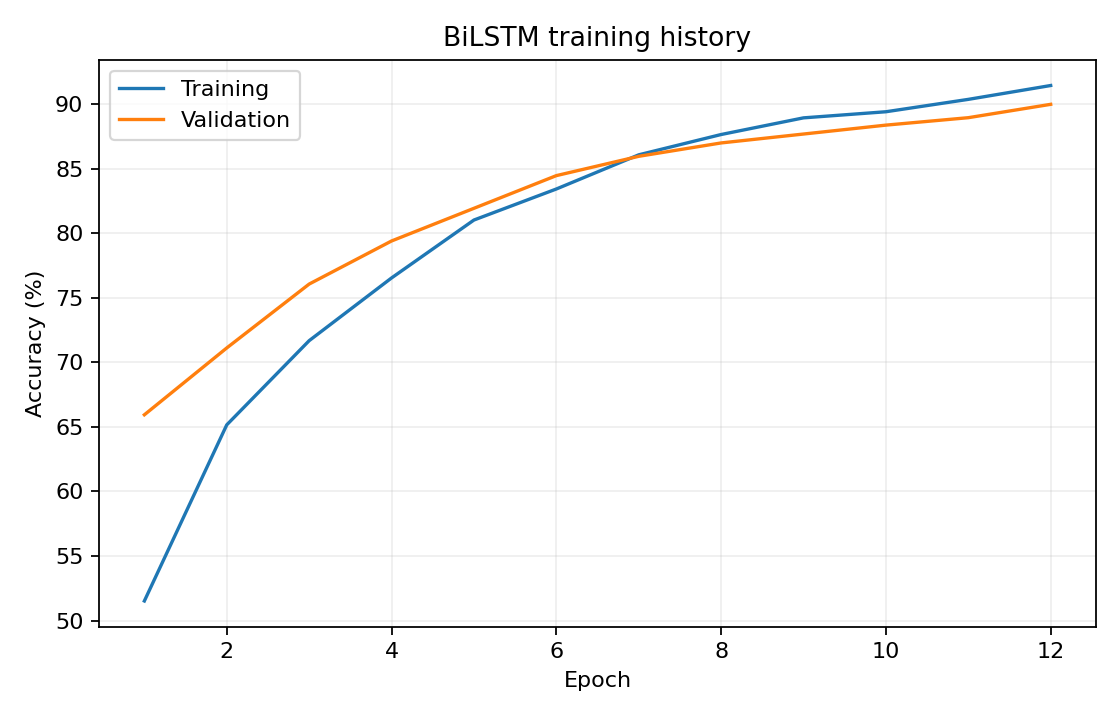

In [8]:
dl=results['schemes']['skema_3_bilstm']
print('Best epoch:',dl['best_epoch'],'Validation:',dl['validation_accuracy'],'Testing:',dl['testing_accuracy'])
display(pd.DataFrame(dl['history']))
display(Image(filename=str(PROJECT_ROOT/'results/figures/bilstm_training_history.png')))

## VIII. Inferensi pada ulasan baru

Enam kalimat baru diuji menggunakan ketiga model. Hasil masing-masing model dan voting mayoritas disajikan sebagai demonstrasi inferensi, bukan sebagai pengganti metrik evaluasi pada testing set.


In [9]:
inf=pd.DataFrame(results['inference'])
display(inf[['input','linear_svc','logreg','bilstm','bilstm_confidence','majority_vote']])
assert inf['majority_vote'].isin(['negatif','netral','positif']).all()

,input,linear_svc,logreg,bilstm,bilstm_confidence,majority_vote
0,"Aplikasi Gojek sangat bagus, mudah digunakan d...",positif,positif,positif,1.0000,positif
1,"GoFood murah, pelayanan sangat memuaskan",positif,positif,positif,0.9972,positif
2,Aplikasi sering error dan sangat mengecewakan,negatif,negatif,negatif,0.9966,negatif
3,"Driver terlalu lama, pesanan saya batal terus",negatif,negatif,negatif,0.9938,negatif
4,Saya menggunakan aplikasi untuk bepergian seti...,netral,netral,netral,0.7976,netral
5,Saya memesan makanan dari restoran dekat kantor,netral,netral,netral,0.5861,netral


## IX. Kesimpulan

- **Model terbaik:** pemilihan didasarkan pada akurasi testing aktual; model deep learning tidak otomatis menghasilkan performa tertinggi.
- **Target akurasi:** batas 92% diperiksa pada training dan testing. Tidak seluruh skema mencapai ambang tersebut.
- **Kualitas label:** pseudo-label leksikon belum menunjukkan validitas terhadap anotasi manusia independen.
- **Perbedaan implementasi:** preprocessing offline berbeda dari pipeline NLTK/PySastrawi sebelumnya; hasil tidak digabungkan antarversi.
- **Integritas data:** teks `text_stem` yang identik telah dihapus sebelum split, meskipun kemiripan semantik masih mungkin ditemukan.
- **Reproduksibilitas:** snapshot CSV dipertahankan karena scraping pada waktu berbeda dapat menghasilkan data yang berubah.


In [10]:
best_key,best=max(results['schemes'].items(),key=lambda kv:kv[1]['testing_accuracy'])
print('Skema terbaik:',best_key,'akurasi testing:',best['testing_accuracy'])
print('Semua skema testing >= 85%:',all(x['testing_accuracy']>=85 for x in results['schemes'].values()))
print('Semua skema training dan testing > 92%:',all(x['training_accuracy']>92 and x['testing_accuracy']>92 for x in results['schemes'].values()))
print('Hasil disimpan dalam results/metrics/, models/, dan results/figures/.')

Skema terbaik: skema_1_linear_svc_tfidf akurasi testing: 92.4988
Semua skema testing >= 85%: True
Semua skema training dan testing > 92%: False
Hasil disimpan dalam results/metrics/, models/, dan results/figures/.
